In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
G = [10, 0, 1]

SIZE = 50
STEPS = 50

#knobs
XI = 2
R = 3
LAM = 2
rho = 0.5


#distribution variables
THETA_MEDIAN = 2
SIGMA_THETA = 1

INSTIGATORS = 0.05
CASCADE_THRESHOLD = 0.2

rng = np.random.default_rng(100)

In [18]:
class Player:

    def __init__(self, id, x, y, strategy, theta, q = 0):
        self.id = id
        self.pos = (x, y)
        #1 defecting, 0 conforming
        self.strategy = int(strategy)
        self.theta = theta
        self.q = float(q)

        self.p_D = 0.0

    def U_m(self, strategy, q):
        if strategy == 1:  # D
            return q * G[0] + (1 - q) * G[1]

        else:  # C
            return q * G[1] + (1 - q) * G[2]

    def U_r(self, strategy, q):
        if strategy == 1:  # D
            return -self.theta * (1 - q)**2

        else:  # C
            return -self.theta * q**2

    def U(self, strategy, q):
        return self.U_m(strategy, q) + self.U_r(strategy, q)
    
    def dU(self, q):
        return self.U(1, q) - self.U(0, q)

    def update(self, signal):
        return self.q + signal

    def choice_probability(self, q, lam):
        delta_u = self.dU(q)

        # Numerical stability
        z = np.clip(lam * delta_u, -30, 30)
        return 1.0 / (1.0 + np.exp(-z))

    def choose(self, p_D, rng):
        self.p_D = float(p_D)
        self.strategy = int(rng.random() < p_D)

In [19]:
class Grid:
    def __init__(self, size = 60, xi = 0.5, R = 5, rho = 0.1, 
                 theta_median = 0.6, theta_std = 0.3, instigators = 0.03):

        self.size = size
        self.xi = xi
        self.R = R
        self.rho = rho

        n = size*size

        state = np.zeros(n, dtype=int)
        n_instigators = int(max(1, n * instigators))
        indices = rng.choice(int(n), size=n_instigators,replace=False)
        state[indices] = 1
        initial_share = state.mean()

        theta_values = rng.lognormal(mean=np.log(theta_median), sigma=theta_std, size=n)

        self.players = []
        self.W = self.build_weights()
        local_D = self.W @ state

        for i in range(n):
            x, y = divmod(i, size)

            player = Player(id=i, x=x, y=y, strategy=state[i], theta=theta_values[i], q=local_D[i])
            self.players.append(player)
        

    def build_weights(self):
        n = self.size
        N = n * n

        W = np.zeros((N, N), dtype=float)

        for i in range(N):
            x1, y1 = divmod(i, n)
            for j in range(N):
                if i == j:
                    continue

                x2, y2 = divmod(j, n)

                # Shortest distance across grid boundaries
                dx = min(abs(x2 - x1), n - abs(x2 - x1))
                dy = min(abs(y2 - y1), n - abs(y2 - y1))

                distance = np.sqrt(dx**2 + dy**2)

                if 0 < distance <= self.R:
                    W[i, j] = np.exp(-distance / self.xi)

            total = W[i].sum()

            if total > 0:
                W[i] /= total
        return W

    def state_array(self):
        return np.array([p.strategy for p in self.players],dtype=int).reshape(self.size, self.size)

    def theta_array(self):
        return np.array([p.theta for p in self.players],dtype=int).reshape(self.size, self.size)

    def q_array(self):
            return np.array([p.q for p in self.players],dtype=int).reshape(self.size, self.size)

    def fraction_D(self):
        return np.mean([p.strategy for p in self.players])

    def local_fraction_D(self):
        state = self.state_array().ravel()
        local = self.W @ state

        return local.reshape(self.size, self.size)

    def step(self):
        old_state = self.state_array().ravel().copy()
        old_q = np.array([p.q for p in self.players])

        local_D = self.W @ old_state

        # Update beliefs without changing any choices yet
        new_q = (1 - self.rho) * old_q + self.rho * local_D

        # Calculate choice probabilities
        probabilities = np.array([p.choice_probability(new_q[i], lam=LAM) for i, p in enumerate(self.players)])

        # Commit all belief updates
        for i, player in enumerate(self.players):
            player.q = new_q[i]
            player.p_D = probabilities[i]

        # Commit all choices using the previous-state snapshot
        for i, player in enumerate(self.players):
            player.choose(probabilities[i], rng)

    def run(self, steps=100, cascade_threshold=0.10):

        fractions = [self.fraction_D()]

        first_crossing = 0 if fractions[0] >= cascade_threshold else None

        for t in range(1, steps + 1):
            self.step()

            share = self.fraction_D()
            fractions.append(share)

            if first_crossing is None and share >= cascade_threshold:
                first_crossing = t

        return {
            "fractions": np.array(fractions),
            "first_crossing": first_crossing,
            "ever_crossed": first_crossing is not None,
            "peak_share": max(fractions)
        }

def plot_grid(grid, title="Grid state"):
    plt.figure(figsize=(6, 6))

    plt.imshow(grid.state_array(), cmap="binary", vmin=0,vmax=1, interpolation="nearest")

    plt.title(title)
    plt.xlabel("Grid column")
    plt.ylabel("Grid row")
    plt.tight_layout()
    plt.show()

def plot_theta(grid):
    plt.figure(figsize=(6, 6))
    
    plt.imshow(grid.theta_array(), cmap="viridis")

    plt.title("Theta state")
    plt.tight_layout()
    plt.show()

def plot_q(grid):
    plt.figure(figsize=(6, 6))
    
    plt.imshow(grid.q_array(), cmap="viridis")

    plt.title("Q state")
    plt.tight_layout()
    plt.show()

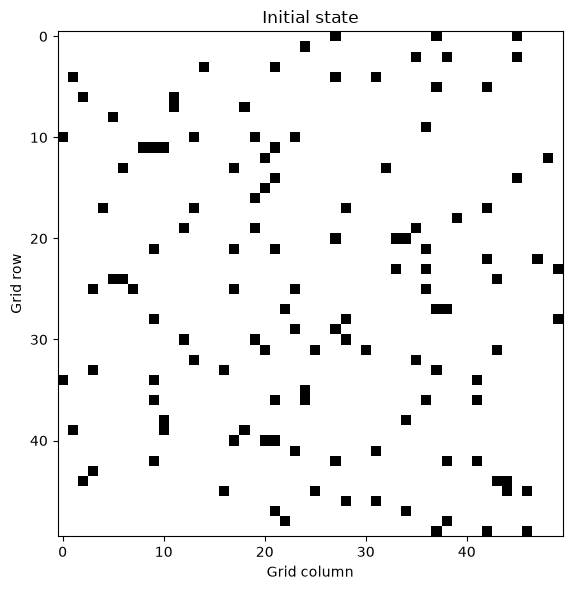

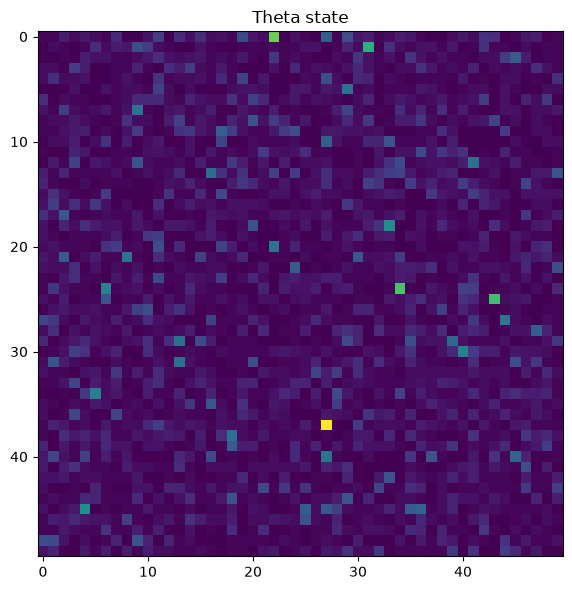

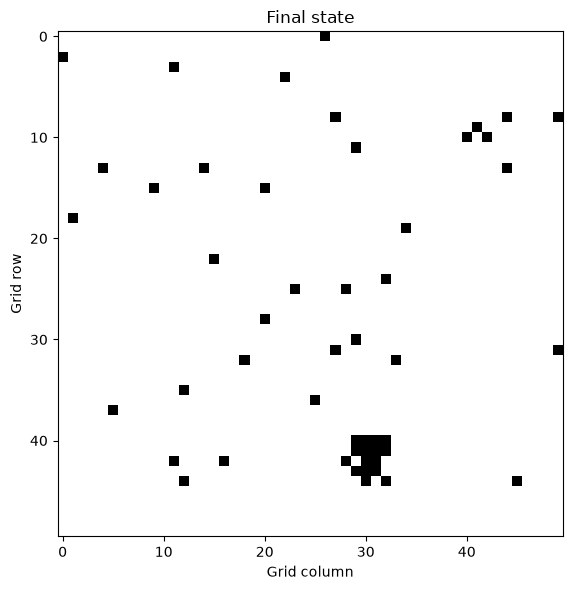

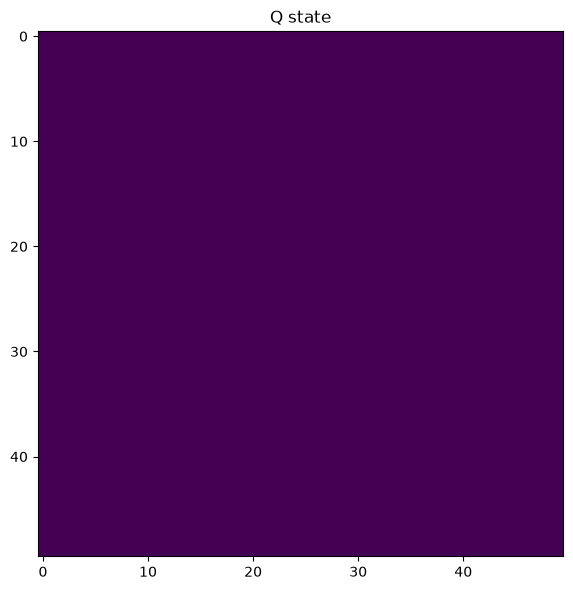

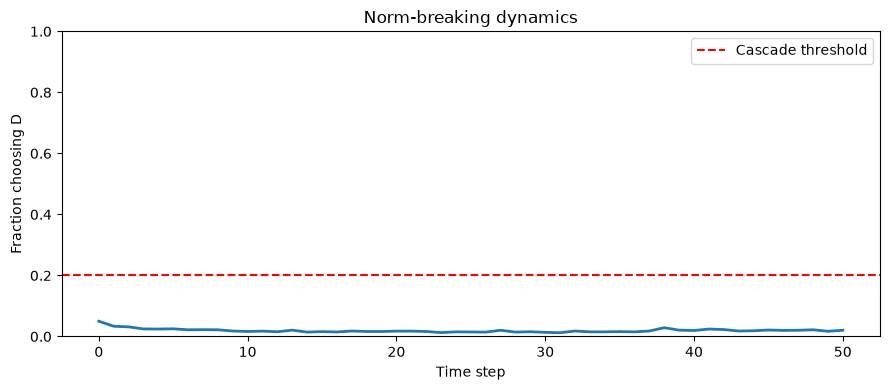

Initial D share: 0.05
Cascade occurred: False
First crossing: None
Peak prevalence: 0.05


In [24]:
G = [6, 0, 1]

if __name__ == "__main__":

    grid = Grid(size=SIZE, xi=XI, R=R, rho = rho, theta_median=THETA_MEDIAN, 
                theta_std=SIGMA_THETA, instigators=INSTIGATORS)

    plot_grid(grid, "Initial state")
    plot_theta(grid)

    result = grid.run(steps=STEPS, cascade_threshold=CASCADE_THRESHOLD)

    plot_grid(grid, "Final state")
    plot_q(grid)

    plt.figure(figsize=(9, 4))

    plt.plot(range(STEPS + 1), result["fractions"], linewidth=2)

    plt.axhline(CASCADE_THRESHOLD, color="red", linestyle="--", label="Cascade threshold")

    plt.xlabel("Time step")
    plt.ylabel("Fraction choosing D")
    plt.title("Norm-breaking dynamics")
    plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Initial D share:", result["fractions"][0])
    print("Cascade occurred:", result["ever_crossed"])
    print("First crossing:", result["first_crossing"])
    print("Peak prevalence:", result["peak_share"])

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------- choice maths (uses your globals G, LAM) ----------------
def dU_vec(q, theta):
    """U_D - U_C, same algebra as Player.dU, but vectorised."""
    q = np.asarray(q, float)
    return (G[0]-G[1])*q + (G[1]-G[2])*(1-q) - theta*((1-q)**2 - q**2)

def p_D_vec(q, theta, lam=None):
    lam = LAM if lam is None else lam
    z = np.clip(lam*dU_vec(q, theta), -30, 30)
    return 1.0/(1.0 + np.exp(-z))

def p_change(q, theta, current, lam=None):
    """current = "C": P(switch to D);  current = "D": P(switch to C)."""
    p = p_D_vec(q, theta, lam)
    return p if current == "C" else 1 - p

def q_star(theta):
    """Belief at which P(D) = 0.5."""
    a, b = G[0]-G[1], G[1]-G[2]
    return (theta - b)/(a - b + 2*theta)


# ---------------- 1. theta vs belief vs P(change) ----------------
def plot_theta_curves(thetas=(0.1, 0.5, 2, 10, 50), lam=None):
    q = np.linspace(0, 1, 400)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
    cols = plt.cm.viridis(np.linspace(0, 0.9, len(thetas)))
    for th, c in zip(thetas, cols):
        ax[0].plot(q, p_change(q, th, "C", lam), color=c,
                   label=f"θ={th:g} (q*={q_star(th):.3f})")
        ax[1].plot(q, p_change(q, th, "D", lam), color=c)
        for a in ax:
            a.axvline(q_star(th), color=c, ls=":", lw=1)
    ax[0].set_title("Player currently C: P(switch to D)")
    ax[1].set_title("Player currently D: P(switch to C)")
    for a in ax:
        a.set_xlabel("belief q_i")
    ax[0].set_ylabel("P(change)"); ax[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()


# ---------------- 2. xi vs belief (xi only acts through q_i) ----------------
def _kernel(xi, R):
    n = int(np.floor(R)); offs, d = [], []
    for dx in range(-n, n+1):
        for dy in range(-n, n+1):
            r = np.hypot(dx, dy)
            if 0 < r <= R:
                offs.append((dx, dy)); d.append(r)
    d = np.array(d)
    w = np.exp(-(d - d.min())/xi)        # equals exp(-d/xi) after normalising
    return offs, w/w.sum()

def local_share(state2d, xi, R):
    """Weighted share of D around every cell (same weights as your build_weights)."""
    offs, w = _kernel(xi, R)
    return sum(wi*np.roll(state2d, o, (0, 1)) for o, wi in zip(offs, w))

def plot_xi_profile(xis=(0.3, 0.5, 1, 2, 5), R=6.0, L=50, block=10,
                    blocks=(4, 8, 12, 20), theta_med=None, theta_lo=0.1, theta_hi=50):
    theta_med = THETA_MEDIAN if theta_med is None else theta_med
    mid, half = L//2, block//2
    state = np.zeros((L, L)); state[mid-half:mid+half, mid-half:mid+half] = 1
    cols = plt.cm.plasma(np.linspace(0, 0.85, len(xis)))
    qs_med = q_star(theta_med)

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
    xs = np.arange(mid-15, mid+15)
    for xi, c in zip(xis, cols):                                   # (a) profile
        ax[0].plot(xs-mid, local_share(state, xi, R)[mid, xs], color=c, label=f"ξ={xi:g}")
    ax[0].axvspan(-half, half-1, color="grey", alpha=0.15, label="D block")
    ax[0].axhspan(q_star(theta_lo), q_star(theta_hi), color="red", alpha=0.08,
                  label="range of tipping points")
    ax[0].axhline(qs_med, color="red", ls="--", lw=1, label="median-θ q*")
    ax[0].set_xlabel("position along row (0 = block centre)"); ax[0].set_ylabel("belief q_i")
    ax[0].set_title(f"(a) q_i across a {block}x{block} D block (R={R:g})"); ax[0].legend(fontsize=8)

    xi_grid = np.logspace(-1, 1, 25)                               # (b), (c) edge player
    for B in blocks:
        st = np.zeros((L, L)); h = B//2
        st[mid-h:mid+h, mid-h:mid+h] = 1
        qe = np.array([local_share(st, xi, R)[mid, mid+h] for xi in xi_grid])
        ax[1].plot(xi_grid, qe, marker=".", label=f"block {B}x{B}")
        ax[2].plot(xi_grid, p_change(qe, theta_med, "C"), marker=".", label=f"block {B}x{B}")
    ax[1].axhline(qs_med, color="red", ls="--", lw=1, label="median-θ q*")
    ax[1].axhline(q_star(0), color="red", ls=":", lw=1, label="floor q* (θ=0)")
    ax[1].set_xscale("log"); ax[1].set_xlabel("ξ"); ax[1].set_ylabel("q_i of edge player")
    ax[1].set_title("(b) belief of a player at the cluster edge"); ax[1].legend(fontsize=8)
    ax[2].set_xscale("log"); ax[2].set_xlabel("ξ"); ax[2].set_ylabel("P(change)")
    ax[2].set_title(f"(c) P(change) of an edge C-player, θ={theta_med:g}"); ax[2].legend(fontsize=8)
    plt.tight_layout(); plt.show()


# ---------------- 3. q_i vs P(change), straight from your Grid ----------------
def plot_q_vs_p(grid):
    q  = np.array([p.q     for p in grid.players])
    th = np.array([p.theta for p in grid.players])
    p  = np.array([p.p_D   for p in grid.players])      # set during grid.step()

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[2, 1]))
    sc = ax[0].scatter(q, p, c=np.log10(th), s=6, cmap="viridis", alpha=0.6)
    plt.colorbar(sc, ax=ax[0], label="log10 θ")
    qq = np.linspace(0, max(1.0, q.max()), 300)
    for pct, ls in [(5, "--"), (50, "-"), (95, ":")]:
        t = np.percentile(th, pct)
        ax[0].plot(qq, p_D_vec(qq, t), "r", ls=ls, lw=1.5, label=f"analytic, θ={t:.2g} (p{pct})")
    ax[0].set_xlabel("belief q_i"); ax[0].set_ylabel("P(D) = P(change) for a C player")
    ax[0].set_title("q_i vs P(change), one dot per player")
    ax[0].legend(fontsize=8); ax[0].set_ylim(-0.02, 1.02)
    ax[1].hist(q, bins=40, alpha=0.8)
    ax[1].set_xlabel("belief q_i"); ax[1].set_ylabel("players"); ax[1].set_title("distribution of q_i")
    plt.tight_layout(); plt.show()

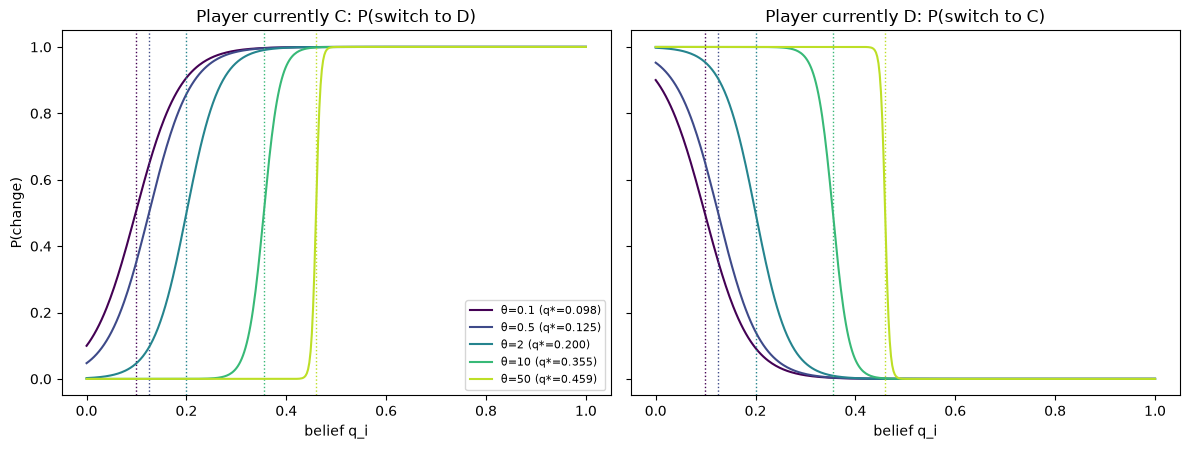

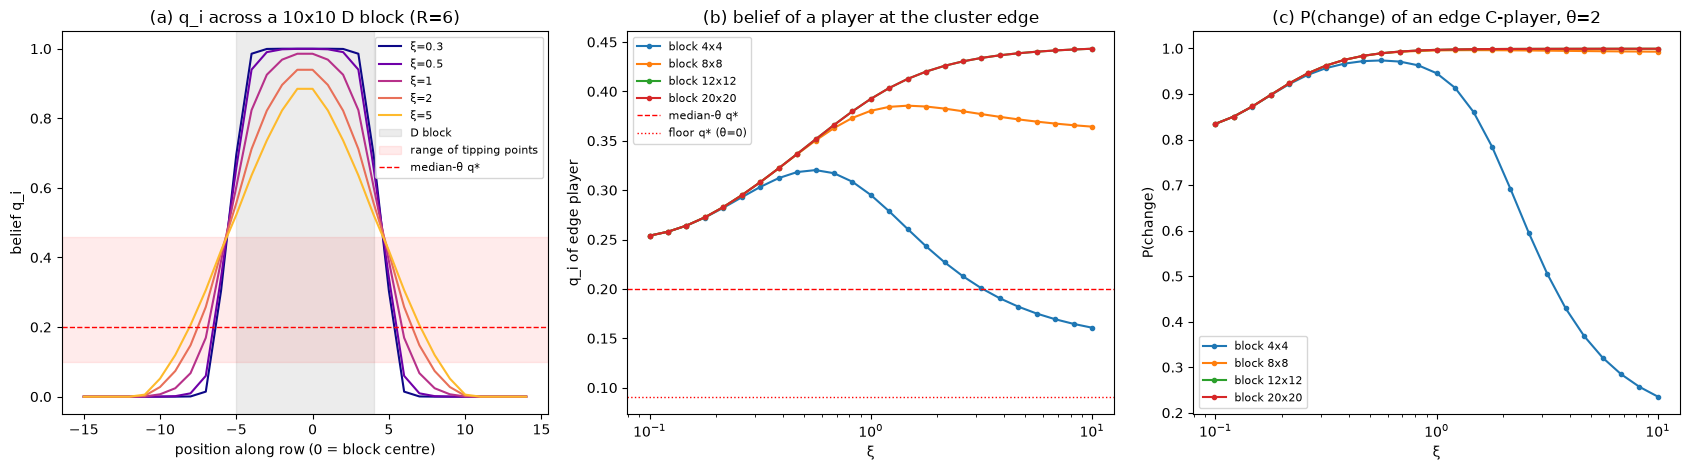

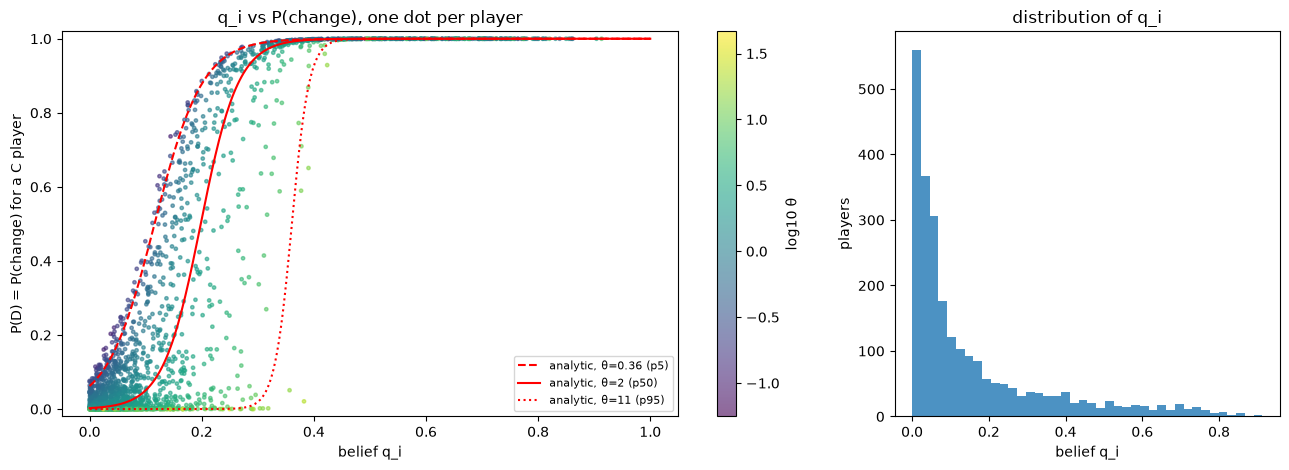

In [22]:
plot_theta_curves()
plot_xi_profile()                 # independent of your grid; uses G, LAM, THETA_MEDIAN
grid = Grid(size=SIZE, xi=XI, R=R, rho = rho, theta_median=THETA_MEDIAN, 
                theta_std=SIGMA_THETA, instigators=INSTIGATORS)
for _ in range(6): grid.step()    # p_D is 0 until the first step
plot_q_vs_p(grid)